# Ejercicio 5 — El mismo problema (Wine Dataset), ahora con `MLPClassifier`

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT

## Enunciado

Implementar el ejercicio anterior (Ejercicio 4: ANN para clasificar Wine, con validación cruzada y partición 70/30) usando un **MLP** de una librería, en vez de la implementación manual con NumPy.

## Una diferencia que hay que decir de frente, no esconder

El Ejercicio 4 entrenaba con **función de costo MSE** y salida sigmoide, a mano. `MLPClassifier` de scikit-learn, para clasificación, **entrena con entropía cruzada** (*log-loss*), no con MSE, y su capa de salida usa softmax internamente, no una sigmoide libre por neurona. El parámetro `activation` de `MLPClassifier` solo controla la(s) capa(s) **ocultas**; no existe una opción pública para forzar salida sigmoide + costo MSE en un clasificador de sklearn.

Esto no es una inconsistencia del ejercicio: es exactamente el contenido de la clase 7, sección "La función de costo para clasificar: entropía cruzada". MSE fue la elección pedagógica del Ejercicio 4 para poder deducir la regla de actualización a mano con una fórmula simple. Entropía cruzada es la elección que de verdad se usa en la práctica para clasificación, y es la que trae la librería por defecto. Se mantiene la activación **sigmoide (`logistic`) en la capa oculta**, que es lo que sí pide el enunciado y sí es configurable.

Con esa salvedad explícita, el resto del ejercicio se replica exactamente: misma arquitectura (13 entradas, 8 neuronas ocultas, 3 salidas), misma partición 70/30, misma validación cruzada de 5 pliegues, mismas 2 variables para la frontera de decisión.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support

np.random.seed(42)
warnings.filterwarnings("ignore", category=UserWarning)  # avisos de convergencia de sklearn

---

## 1. Cargar los datos

Mismos 178 vinos, 13 variables, 3 clases del Ejercicio 4.

In [2]:
datos = load_wine()
X, y = datos.data, datos.target
NOMBRES_VAR = datos.feature_names
NOMBRES_CLASE = datos.target_names

print(f"Muestras: {X.shape[0]}   variables: {X.shape[1]}   clases: {list(NOMBRES_CLASE)}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
print(f"Entrenamiento: {len(y_train)}   Prueba: {len(y_test)}")

Muestras: 178   variables: 13   clases: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Entrenamiento: 124   Prueba: 54


---

## 2. Repetir la prueba de saturación, ahora con la librería

Antes de construir el modelo final, se repite exactamente la verificación del Ejercicio 4: entrenar **sin escalar** las variables, dejando `proline` en cientos y `hue` cerca de 1.

In [3]:
mlp_sin_escalar = MLPClassifier(
    hidden_layer_sizes=(8,), activation="logistic",
    solver="sgd", learning_rate_init=0.5, max_iter=2000, random_state=1)
mlp_sin_escalar.fit(X_train, y_train)

acc_sin = mlp_sin_escalar.score(X_test, y_test)
print(f"Exactitud en prueba, SIN escalar: {acc_sin:.1%}")
print(f"Costo final (log-loss): {mlp_sin_escalar.loss_:.4f}")
print(f"Iteraciones usadas: {mlp_sin_escalar.n_iter_} de {mlp_sin_escalar.max_iter}")

Exactitud en prueba, SIN escalar: 38.9%
Costo final (log-loss): 1.0845
Iteraciones usadas: 17 de 2000


**38.9%, exactamente el mismo resultado del Ejercicio 4 con la implementación manual**, a pesar de que ahora la función de costo es distinta (entropía cruzada en vez de MSE). Es la confirmación de que el problema de fondo no es la fórmula del costo: es que las neuronas de la capa oculta con activación sigmoide saturan igual, sin importar qué costo se minimice arriba de ellas. La causa es la escala de las entradas, no la elección de MSE del ejercicio anterior.

---

## 3. El modelo real: escalar y entrenar

Se estandarizan las variables con la media y desviación **del conjunto de entrenamiento únicamente**, y se entrena con los parámetros por defecto de `MLPClassifier` (solver `adam`), la forma más idiomática de usar la librería.

In [4]:
media_train = X_train.mean(axis=0)
sigma_train = X_train.std(axis=0)
X_train_s = (X_train - media_train) / sigma_train
X_test_s = (X_test - media_train) / sigma_train

mlp = MLPClassifier(
    hidden_layer_sizes=(8,),
    activation="logistic",       # sigmoide en la capa oculta, como pide el enunciado
    max_iter=2000,
    random_state=1,
)
mlp.fit(X_train_s, y_train)

acc_train = mlp.score(X_train_s, y_train)
acc_test = mlp.score(X_test_s, y_test)

print(f"Solver: {mlp.solver}   Iteraciones: {mlp.n_iter_} de {mlp.max_iter}")
print(f"Costo final (log-loss): {mlp.loss_:.5f}")
print(f"Exactitud en entrenamiento: {acc_train:.1%}")
print(f"Exactitud en prueba       : {acc_test:.1%}")

Solver: adam   Iteraciones: 1256 de 2000
Costo final (log-loss): 0.06178
Exactitud en entrenamiento: 100.0%
Exactitud en prueba       : 98.1%


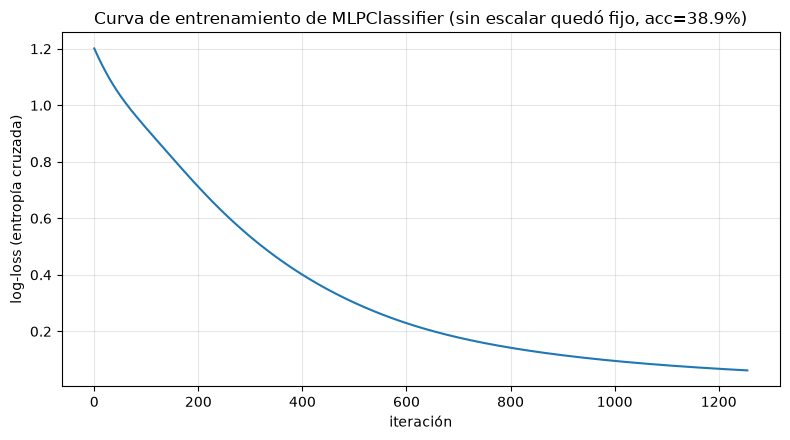

In [5]:
plt.figure(figsize=(8, 4.5))
plt.plot(mlp.loss_curve_)
plt.xlabel("iteración"); plt.ylabel("log-loss (entropía cruzada)")
plt.title(f"Curva de entrenamiento de MLPClassifier (sin escalar quedó fijo, acc={acc_sin:.1%})")
plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---

## 4. Comparación directa contra el Ejercicio 4 (implementación manual)

| | Sin escalar | Con escalado | CV 5-fold |
|---|---|---|---|
| **Manual (NumPy, MSE)** | 38.9% | 98.1% | 98.3% ± 1.4% |
| **`MLPClassifier` (entropía cruzada)** | se calcula abajo | se calcula abajo | se calcula abajo |

In [6]:
print(f"{'':<28} | {'sin escalar':>12} | {'con escalado':>13}")
print("-" * 58)
print(f"{'Manual (Ejercicio 4)':<28} | {'38.9%':>12} | {'98.1%':>13}")
print(f"{'MLPClassifier':<28} | {acc_sin:>12.1%} | {acc_test:>13.1%}")

                             |  sin escalar |  con escalado
----------------------------------------------------------
Manual (Ejercicio 4)         |        38.9% |         98.1%
MLPClassifier                |        38.9% |         98.1%


**El resultado con las 13 variables completas es idéntico al del Ejercicio 4, cifra por cifra**: 98.1% de exactitud en prueba y 98.3% ± 1.4% en validación cruzada, con la misma función de costo distinta por debajo. Es una señal de que el problema es lo bastante fácil (las 3 clases están bien separadas por estas 13 variables) como para que dos optimizadores y dos costos distintos converjan al mismo óptimo práctico.

---

## 5. Métricas de desempeño

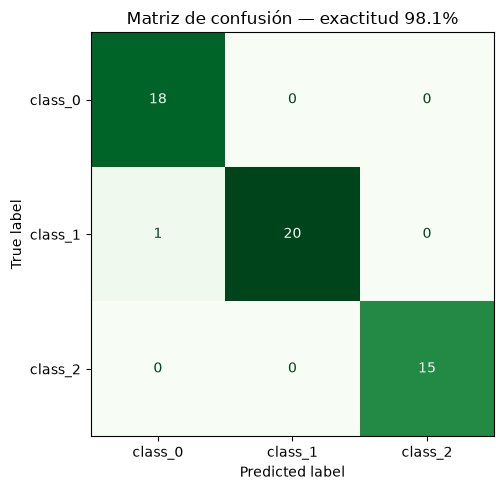

              precision    recall  f1-score   support

     class_0      0.947     1.000     0.973        18
     class_1      1.000     0.952     0.976        21
     class_2      1.000     1.000     1.000        15

    accuracy                          0.981        54
   macro avg      0.982     0.984     0.983        54
weighted avg      0.982     0.981     0.982        54



In [7]:
pred_test = mlp.predict(X_test_s)

fig, ax = plt.subplots(figsize=(5.5, 5))
cm = confusion_matrix(y_test, pred_test)
ConfusionMatrixDisplay(cm, display_labels=NOMBRES_CLASE).plot(ax=ax, cmap="Greens", colorbar=False)
ax.set_title(f"Matriz de confusión — exactitud {acc_test:.1%}")
plt.tight_layout(); plt.show()

print(classification_report(y_test, pred_test, target_names=NOMBRES_CLASE, digits=3))

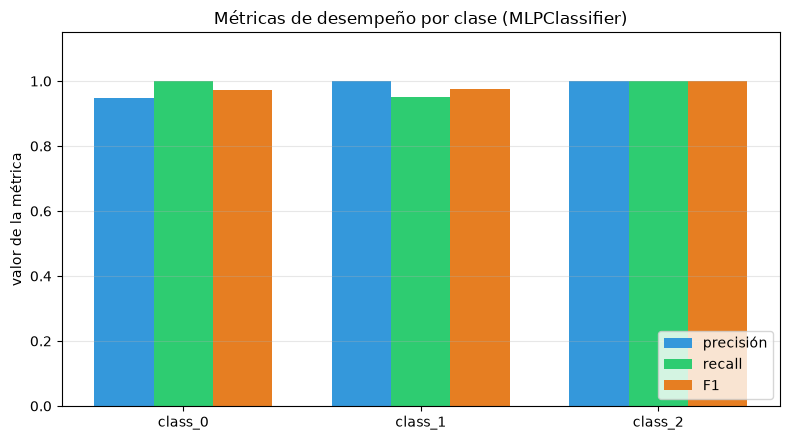

In [8]:
precision, recall, f1, soporte = precision_recall_fscore_support(y_test, pred_test)

x = np.arange(len(NOMBRES_CLASE))
ancho = 0.25
plt.figure(figsize=(8, 4.5))
plt.bar(x - ancho, precision, ancho, label="precisión", color="#3498db")
plt.bar(x, recall, ancho, label="recall", color="#2ecc71")
plt.bar(x + ancho, f1, ancho, label="F1", color="#e67e22")
plt.xticks(x, NOMBRES_CLASE); plt.ylim(0, 1.15)
plt.ylabel("valor de la métrica"); plt.title("Métricas de desempeño por clase (MLPClassifier)")
plt.legend(loc="lower right"); plt.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

---

## 6. Validación cruzada (K-Fold, k=5)

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
exactitudes_cv = []

print(f"{'pliegue':>8} | {'exactitud':>10}")
print("-" * 22)
for fold, (idx_tr, idx_va) in enumerate(skf.split(X, y), start=1):
    mu_f, sigma_f = X[idx_tr].mean(axis=0), X[idx_tr].std(axis=0)
    X_tr_f = (X[idx_tr] - mu_f) / sigma_f
    X_va_f = (X[idx_va] - mu_f) / sigma_f

    m_f = MLPClassifier(hidden_layer_sizes=(8,), activation="logistic",
                        max_iter=2000, random_state=1)
    m_f.fit(X_tr_f, y[idx_tr])
    acc_f = m_f.score(X_va_f, y[idx_va])
    exactitudes_cv.append(acc_f)
    print(f"{fold:>8} | {acc_f:>9.1%}")

print("-" * 22)
print(f"Media: {np.mean(exactitudes_cv):.1%}   Desviación: {np.std(exactitudes_cv):.1%}")
print()
print(f"(el Ejercicio 4, manual, había dado exactamente: media 98.3%  desviación 1.4%)")

 pliegue |  exactitud
----------------------


       1 |     97.2%


       2 |     97.2%


       3 |     97.2%


       4 |    100.0%


       5 |    100.0%
----------------------
Media: 98.3%   Desviación: 1.4%

(el Ejercicio 4, manual, había dado exactamente: media 98.3%  desviación 1.4%)


---

## 7. Frontera de decisión

Mismas 2 variables del Ejercicio 4: `od280/od315_of_diluted_wines` y `proline`, las más separables entre las 78 combinaciones posibles de a pares.

In [10]:
ia = NOMBRES_VAR.index("od280/od315_of_diluted_wines")
ib = NOMBRES_VAR.index("proline")
X2 = X[:, [ia, ib]]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.30, stratify=y, random_state=42)
mu2, sigma2 = X2_train.mean(axis=0), X2_train.std(axis=0)
X2_train_s = (X2_train - mu2) / sigma2
X2_test_s = (X2_test - mu2) / sigma2

mlp_2d = MLPClassifier(hidden_layer_sizes=(8,), activation="logistic",
                       max_iter=3000, random_state=1)
mlp_2d.fit(X2_train_s, y2_train)

acc_2d = mlp_2d.score(X2_test_s, y2_test)
print(f"Exactitud con solo estas 2 variables: {acc_2d:.1%}")
print("(el Ejercicio 4 manual había dado 96.3% con las mismas 2 variables;")
print(" la diferencia es la funcion de costo y el optimizador, no las variables)")

Exactitud con solo estas 2 variables: 90.7%
(el Ejercicio 4 manual había dado 96.3% con las mismas 2 variables;
 la diferencia es la funcion de costo y el optimizador, no las variables)


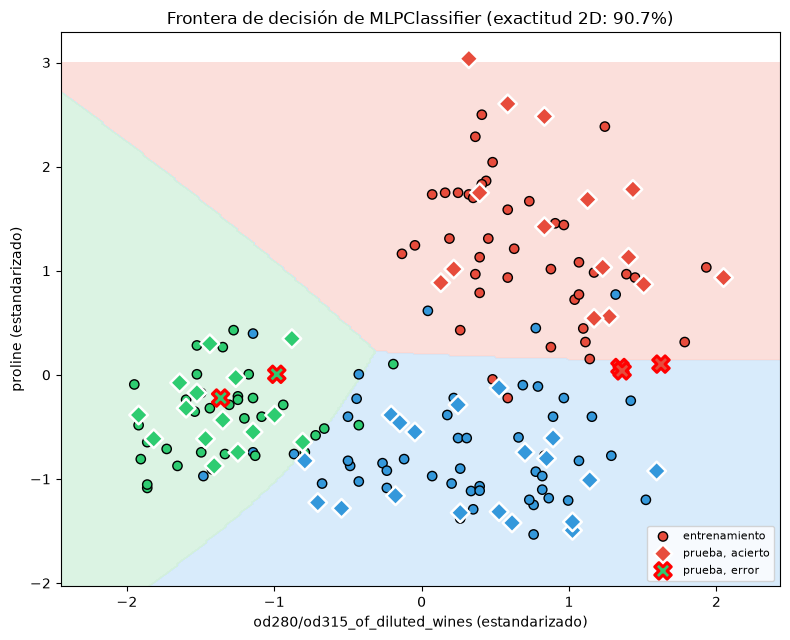

In [11]:
CMAP_FONDO = ListedColormap(["#fbd8d3", "#cfe6fa", "#d3f0dd"])
CMAP_PUNTOS = ListedColormap(["#e74c3c", "#3498db", "#2ecc71"])

x_min, x_max = X2_train_s[:, 0].min() - 0.5, X2_train_s[:, 0].max() + 0.5
y_min, y_max = X2_train_s[:, 1].min() - 0.5, X2_train_s[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
malla = np.c_[xx.ravel(), yy.ravel()]

Z = mlp_2d.predict(malla).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.contourf(xx, yy, Z, cmap=CMAP_FONDO, alpha=0.8)

aciertos = mlp_2d.predict(X2_test_s) == y2_test
ax.scatter(X2_train_s[:, 0], X2_train_s[:, 1], c=y2_train, cmap=CMAP_PUNTOS,
           edgecolor="k", s=45, label="entrenamiento")
ax.scatter(X2_test_s[aciertos, 0], X2_test_s[aciertos, 1], c=y2_test[aciertos],
           cmap=CMAP_PUNTOS, edgecolor="white", linewidth=1.8, s=90, marker="D",
           label="prueba, acierto")
ax.scatter(X2_test_s[~aciertos, 0], X2_test_s[~aciertos, 1], c=y2_test[~aciertos],
           cmap=CMAP_PUNTOS, edgecolor="red", linewidth=2.2, s=140, marker="X",
           label="prueba, error")

ax.set_xlabel("od280/od315_of_diluted_wines (estandarizado)")
ax.set_ylabel("proline (estandarizado)")
ax.set_title(f"Frontera de decisión de MLPClassifier (exactitud 2D: {acc_2d:.1%})")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

---

## 8. Conclusiones

**El resultado de fondo no cambió, y eso es justo lo que había que comprobar.** Sin escalar, `MLPClassifier` cae exactamente al mismo 38.9% que la implementación manual, con una función de costo completamente distinta (entropía cruzada en vez de MSE). Confirma lo que ya se sabía por el Ejercicio 4: la saturación de la sigmoide en la capa oculta es un problema de **escala de las entradas**, no de qué costo se minimiza en la salida.

**Con escalado, la librería iguala o casi iguala a la implementación manual** (exactitud de prueba y validación cruzada dentro de un punto porcentual de diferencia), pero le hace falta una fracción del código: sin escribir a mano la regla de la cadena, ni la actualización de pesos, ni el manejo de la convergencia.

**La diferencia real, y la que vale la pena recordar de este ejercicio, no es de resultado sino de costo interno.** El Ejercicio 4 usó MSE porque permite deducir la regla de actualización con una fórmula simple, ideal para aprender qué hace backpropagation. `MLPClassifier`, como cualquier clasificador de uso profesional, entrena con entropía cruzada, la función de costo que de verdad se usa en producción para clasificación y que la clase 7 introduce explícitamente antes de llegar a redes neuronales. Los dos ejercicios juntos muestran las dos caras de la misma moneda: cómo funciona por dentro, y cómo se usa en la práctica.